In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os
import pickle

from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from wordcloud import WordCloud

import warnings
warnings.filterwarnings("ignore")

In [2]:
real_fake = pd.read_csv("real_fake_jobs.csv")
fake10k = pd.read_csv("fake_jobs_10k.csv")

print("Real/Fake dataset:")
print(real_fake.shape)

print("\n10K Fake dataset:")
print(fake10k.shape)

Real/Fake dataset:
(17880, 18)

10K Fake dataset:
(10000, 10)


In [3]:
#Exploring real/fake dataset
real_fake.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [4]:
real_fake.columns.tolist()

['job_id',
 'title',
 'location',
 'department',
 'salary_range',
 'company_profile',
 'description',
 'requirements',
 'benefits',
 'telecommuting',
 'has_company_logo',
 'has_questions',
 'employment_type',
 'required_experience',
 'required_education',
 'industry',
 'function',
 'fraudulent']

In [5]:
real_fake.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [6]:
real_fake["fraudulent"].value_counts()

,count
fraudulent,
0,17014
1,866


In [7]:
real_fake["fraudulent"].value_counts(normalize=True) * 100

,proportion
fraudulent,
0,95.1566
1,4.8434


In [8]:
#Exploring fake jobs dataset
fake10k.head()

,title,description,requirements,company_profile,location,salary_range,employment_type,industry,benefits,fraudulent
0,Mental health nurse,Arm drive court sure vote. Earn $5000/week! Im...,"Basic knowledge in live, no degree required. F...",Rivera and Sons - Established 2022.,West Jeffrey,$55016-$100476,Internship,IT,Free meals,1
1,Conference centre manager,Government whom its bed go tax tree black. Ear...,"Basic knowledge in seek, no degree required. F...","Davidson, Jones and Gomez - Established 2003.",Lake Meredithberg,$53438-$93138,Part-Time,Finance,Flexible hours,1
2,"Engineer, land",I member discuss follow way there nation. Earn...,"Basic knowledge in worker, no degree required....",Allen Ltd - Established 1998.,Lake Cathybury,$45584-$105229,Part-Time,IT,Free travel,1
3,Forest/woodland manager,House across wait approach face. Earn $5000/we...,"Basic knowledge in example, no degree required...",Forbes Ltd - Established 1990.,South Matthewstad,$66188-$139621,Full-Time,Education,Free travel,1
4,"Production designer, theatre/television/film",Case best environmental full finally leader me...,"Basic knowledge in smile, no degree required. ...","Jennings, Martin and Sanchez - Established 1975.",East Rhondafurt,$32183-$115012,Temporary,Retail,Flexible hours,1


In [9]:
fake10k.columns.tolist()

['title',
 'description',
 'requirements',
 'company_profile',
 'location',
 'salary_range',
 'employment_type',
 'industry',
 'benefits',
 'fraudulent']

In [10]:
fake10k.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   title            10000 non-null  object
 1   description      10000 non-null  object
 2   requirements     10000 non-null  object
 3   company_profile  10000 non-null  object
 4   location         10000 non-null  object
 5   salary_range     10000 non-null  object
 6   employment_type  10000 non-null  object
 7   industry         10000 non-null  object
 8   benefits         10000 non-null  object
 9   fraudulent       10000 non-null  int64 
dtypes: int64(1), object(9)
memory usage: 781.4+ KB


In [11]:
#checking missing values

real_fake.isnull().sum().sort_values(ascending=False)

,0
salary_range,15012
department,11547
required_education,8105
benefits,7212
required_experience,7050
function,6455
industry,4903
employment_type,3471
company_profile,3308
requirements,2696


In [13]:
fake10k.isnull().sum().sort_values(ascending=False)

,0
title,0
description,0
requirements,0
company_profile,0
location,0
salary_range,0
employment_type,0
industry,0
benefits,0
fraudulent,0


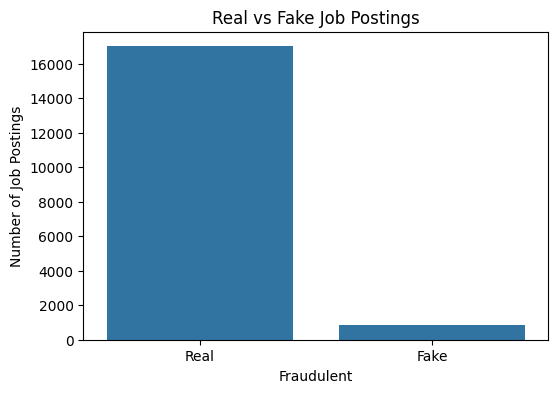

In [19]:
#looking at class distribution

plt.figure(figsize=(6,4))

sns.countplot(
    x="fraudulent",
    data=real_fake
)

plt.title("Real vs Fake Job Postings")
plt.xlabel("Fraudulent")
plt.ylabel("Number of Job Postings")
plt.xticks([0, 1], ["Real", "Fake"])

plt.show()

In [20]:
text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

real_fake["full_text"] = (
    real_fake["title"].fillna("") + " " +
    real_fake["company_profile"].fillna("") + " " +
    real_fake["description"].fillna("") + " " +
    real_fake["requirements"].fillna("") + " " +
    real_fake["benefits"].fillna("")
)

print(real_fake[["title", "full_text"]].head())

                                       title  \
0                           Marketing Intern   
1  Customer Service - Cloud Video Production   
2    Commissioning Machinery Assistant (CMA)   
3          Account Executive - Washington DC   
4                        Bill Review Manager   

                                           full_text  
0  Marketing Intern We're Food52, and we've creat...  
1  Customer Service - Cloud Video Production 90 S...  
2  Commissioning Machinery Assistant (CMA) Valor ...  
3  Account Executive - Washington DC Our passion ...  
4  Bill Review Manager SpotSource Solutions LLC i...  


In [23]:
fake_text_columns = [
    "title",
    "company_profile",
    "description",
    "requirements",
    "benefits"
]

fake10k["full_text"] = (
    fake10k["title"].fillna("") + " " +
    fake10k["company_profile"].fillna("") + " " +
    fake10k["description"].fillna("") + " " +
    fake10k["requirements"].fillna("") + " " +
    fake10k["benefits"].fillna("")
)

print(fake10k[["title", "full_text"]].head())

                                          title  \
0                           Mental health nurse   
1                     Conference centre manager   
2                                Engineer, land   
3                       Forest/woodland manager   
4  Production designer, theatre/television/film   

                                           full_text  
0  Mental health nurse Rivera and Sons - Establis...  
1  Conference centre manager Davidson, Jones and ...  
2  Engineer, land Allen Ltd - Established 1998. I...  
3  Forest/woodland manager Forbes Ltd - Establish...  
4  Production designer, theatre/television/film J...  


In [25]:
#Cleaning and removing unnecessary text

import re

def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [26]:
real_fake["clean_text"] = real_fake["full_text"].apply(clean_text)

fake10k["clean_text"] = fake10k["full_text"].apply(clean_text)

In [27]:
print(real_fake["clean_text"].iloc[0])

marketing intern we re food and we ve created a groundbreaking and award winning cooking site we support connect and celebrate home cooks and give them everything they need in one place we have a top editorial business and engineering team we re focused on using technology to find new and better ways to connect people around their specific food interests and to offer them superb highly curated information about food and cooking we attract the most talented home cooks and contributors in the country we also publish well known professionals like mario batali gwyneth paltrow and danny meyer and we have partnerships with whole foods market and random house food has been named the best food website by the james beard foundation and iacp and has been featured in the new york times npr pando daily techcrunch and on the today show we re located in chelsea in new york city food a fast growing james beard award winning online food community and crowd sourced and curated recipe hub is currently i

In [28]:
print(fake10k["clean_text"].iloc[0])

mental health nurse rivera and sons established arm drive court sure vote earn week immediate hiring contact now at basic knowledge in live no degree required flexible hours free meals


In [29]:
from collections import Counter

In [30]:
#counting frequency of words

all_fake_text = " ".join(fake10k["clean_text"])

words = all_fake_text.split()

word_counts = Counter(words)

common_words = word_counts.most_common(20)

common_words_df = pd.DataFrame(
    common_words,
    columns=["word", "count"]
)

print(common_words_df)

           word  count
0      flexible  11968
1         hours  11968
2            no  10089
3           now  10073
4        degree  10072
5          week  10067
6     knowledge  10064
7            at  10059
8            in  10057
9   established  10000
10         earn  10000
11    immediate  10000
12       hiring  10000
13      contact  10000
14        basic  10000
15     required  10000
16          and   4230
17         free   4055
18           on   2140
19         sign   2138


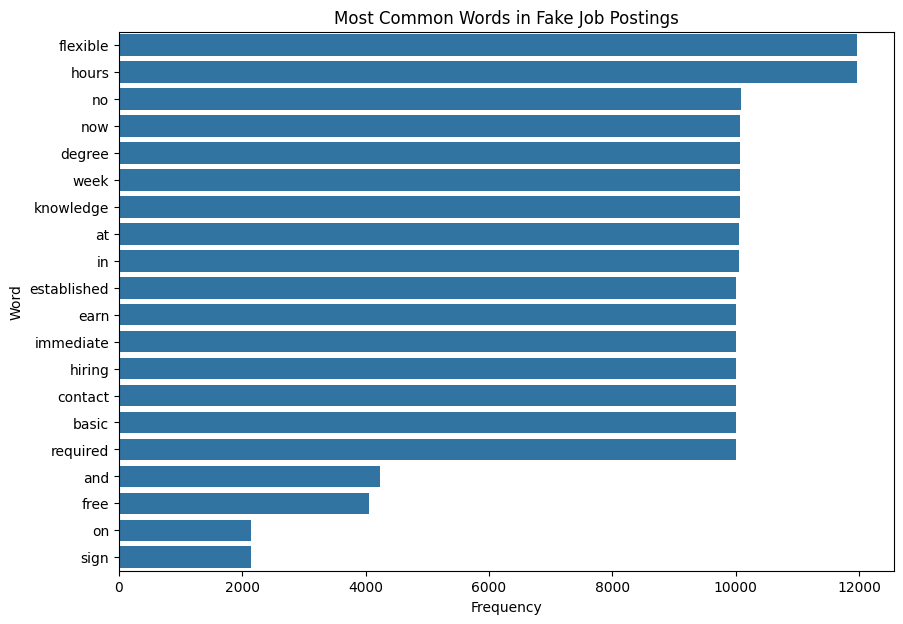

In [31]:
#visualising most common words

plt.figure(figsize=(10, 7))

sns.barplot(
    data=common_words_df,
    x="count",
    y="word"
)

plt.title("Most Common Words in Fake Job Postings")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

In [32]:
#words not as useful so looking at phrases next

from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    max_features=30
)

bigram_matrix = bigram_vectorizer.fit_transform(
    fake10k["clean_text"]
)

bigram_counts = np.asarray(
    bigram_matrix.sum(axis=0)
).flatten()

bigrams = pd.DataFrame({
    "phrase": bigram_vectorizer.get_feature_names_out(),
    "count": bigram_counts
})

bigrams = bigrams.sort_values(
    "count",
    ascending=False
)

print(bigrams.head(20))

                phrase  count
7       flexible hours  11968
0      basic knowledge  10000
4            earn week  10000
3      degree required  10000
11      hiring contact  10000
2        contact basic  10000
22   required flexible  10000
27      week immediate  10000
16    immediate hiring  10000
13          hours free   3979
18    knowledge degree   2171
15          hours sign   2067
24          sign bonus   2067
9          free travel   1994
29  work opportunities   1986
14        hours remote   1986
21         remote work   1986
8           free meals   1985
12      hours flexible   1968
20     plc established    596


In [33]:
pip install wordcloud

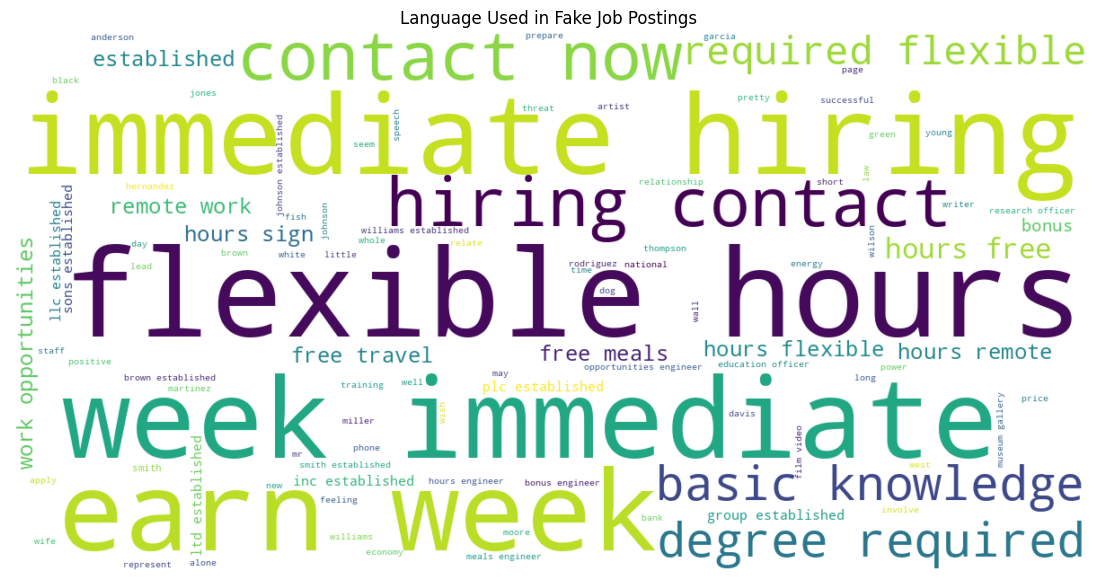

In [34]:
#visualising most used phrases in fake job postings using a wordcloud

from wordcloud import WordCloud

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    max_words=100
).generate(all_fake_text)

plt.figure(figsize=(15, 7))

plt.imshow(
    wordcloud,
    interpolation="bilinear"
)

plt.axis("off")

plt.title("Language Used in Fake Job Postings")

plt.show()

In [35]:
#training ML model using real-fake dataset

X = real_fake["clean_text"]
y = real_fake["fraudulent"]

In [36]:
#splitting dataset into training and testing (stratify is imp as it maintains the real/fake ratio is the split)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 14304
Testing samples: 3576


In [37]:
#convert text into numbers for ML modelling

from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

In [38]:
X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)

Training matrix shape: (14304, 10000)
Testing matrix shape: (3576, 10000)


In [39]:
#model 1: logistic regression

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

logistic_model.fit(
    X_train_tfidf,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [40]:
lr_predictions = logistic_model.predict(X_test_tfidf)

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

lr_accuracy = accuracy_score(
    y_test,
    lr_predictions
)

lr_precision = precision_score(
    y_test,
    lr_predictions
)

lr_recall = recall_score(
    y_test,
    lr_predictions
)

lr_f1 = f1_score(
    y_test,
    lr_predictions
)

print("Accuracy:", lr_accuracy)
print("Precision:", lr_precision)
print("Recall:", lr_recall)
print("F1 Score:", lr_f1)

print("\nClassification Report:")
print(classification_report(y_test, lr_predictions))

Accuracy: 0.977069351230425
Precision: 0.7058823529411765
Recall: 0.9017341040462428
F1 Score: 0.7918781725888325

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99      3403
           1       0.71      0.90      0.79       173

    accuracy                           0.98      3576
   macro avg       0.85      0.94      0.89      3576
weighted avg       0.98      0.98      0.98      3576



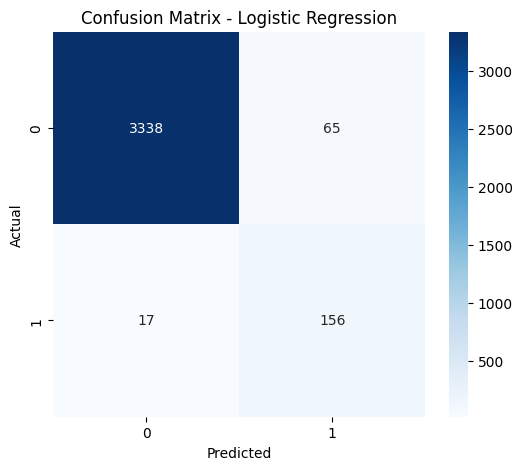

In [42]:
#creating a confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    lr_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [43]:
#model 2: naive bayes

from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(
    X_train_tfidf,
    y_train
)

nb_predictions = nb_model.predict(
    X_test_tfidf
)

In [44]:
#model 3: linear SVM

from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    class_weight="balanced"
)

svm_model.fit(
    X_train_tfidf,
    y_train
)

svm_predictions = svm_model.predict(
    X_test_tfidf
)

In [45]:
#comparing three models

model_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "Linear SVM"
    ],

    "Accuracy": [
        accuracy_score(y_test, lr_predictions),
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, svm_predictions)
    ],

    "Precision": [
        precision_score(y_test, lr_predictions),
        precision_score(y_test, nb_predictions),
        precision_score(y_test, svm_predictions)
    ],

    "Recall": [
        recall_score(y_test, lr_predictions),
        recall_score(y_test, nb_predictions),
        recall_score(y_test, svm_predictions)
    ],

    "F1 Score": [
        f1_score(y_test, lr_predictions),
        f1_score(y_test, nb_predictions),
        f1_score(y_test, svm_predictions)
    ]
})

model_results = model_results.sort_values(
    "F1 Score",
    ascending=False
)

print(model_results)

                 Model  Accuracy  Precision    Recall  F1 Score
2           Linear SVM  0.984620   0.851190  0.826590  0.838710
0  Logistic Regression  0.977069   0.705882  0.901734  0.791878
1          Naive Bayes  0.960291   0.666667  0.358382  0.466165


In [46]:
#making linear svm our final model

best_model = svm_model

In [47]:
svm_predictions = best_model.predict(X_test_tfidf)

print(classification_report(
    y_test,
    svm_predictions
))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      3403
           1       0.85      0.83      0.84       173

    accuracy                           0.98      3576
   macro avg       0.92      0.91      0.92      3576
weighted avg       0.98      0.98      0.98      3576



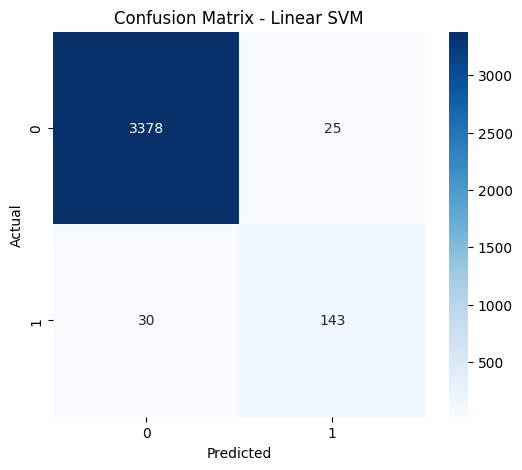

In [48]:
#confusion matrix for liner SVM

from sklearn.metrics import confusion_matrix

svm_cm = confusion_matrix(
    y_test,
    svm_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Confusion Matrix - Linear SVM")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [49]:
#analysing which words svm associates with fake jobs

feature_names = vectorizer.get_feature_names_out()

coefficients = best_model.coef_[0]

feature_importance = pd.DataFrame({
    "word": feature_names,
    "coefficient": coefficients
})

In [50]:
#words most associated with fake jobs
fake_words = feature_importance.sort_values(
    "coefficient",
    ascending=False
).head(20)

print("Words most associated with fake jobs:")
print(fake_words)

Words most associated with fake jobs:
                   word  coefficient
5129               link     2.868981
516            aptitude     1.947116
4187        high school     1.846940
109          accountant     1.805258
517   aptitude staffing     1.798815
377      amp experience     1.708757
5716              money     1.696927
7722    sales executive     1.692903
2236                 db     1.672209
8604             subsea     1.658566
1419              clerk     1.456903
7255       receptionist     1.446867
8666           supplier     1.443160
8148              sites     1.439766
9067          time time     1.433304
9417                 ux     1.430262
5006               lean     1.429370
9232               type     1.419139
1328  change management     1.404384
5819          nbsp nbsp     1.401288


In [51]:
#words most associated with real jobs

real_words = feature_importance.sort_values(
    "coefficient",
    ascending=True
).head(20)

print("Words most associated with real jobs:")
print(real_words)

Words most associated with real jobs:
                word  coefficient
3009         english    -1.691253
1610       companies    -1.627570
744            based    -1.360676
3782             fun    -1.312029
6838     procurement    -1.300597
4589    installation    -1.295759
1445         clients    -1.276844
8244        software    -1.252258
1122              ca    -1.248187
2547         digital    -1.238912
7290     recruitment    -1.221016
2108          custom    -1.219154
761   basic computer    -1.177038
4162           helps    -1.152735
2228            days    -1.151789
5135            list    -1.145876
8798            team    -1.135111
8115            sign    -1.131930
4065        handling    -1.089013
9301      university    -1.077013


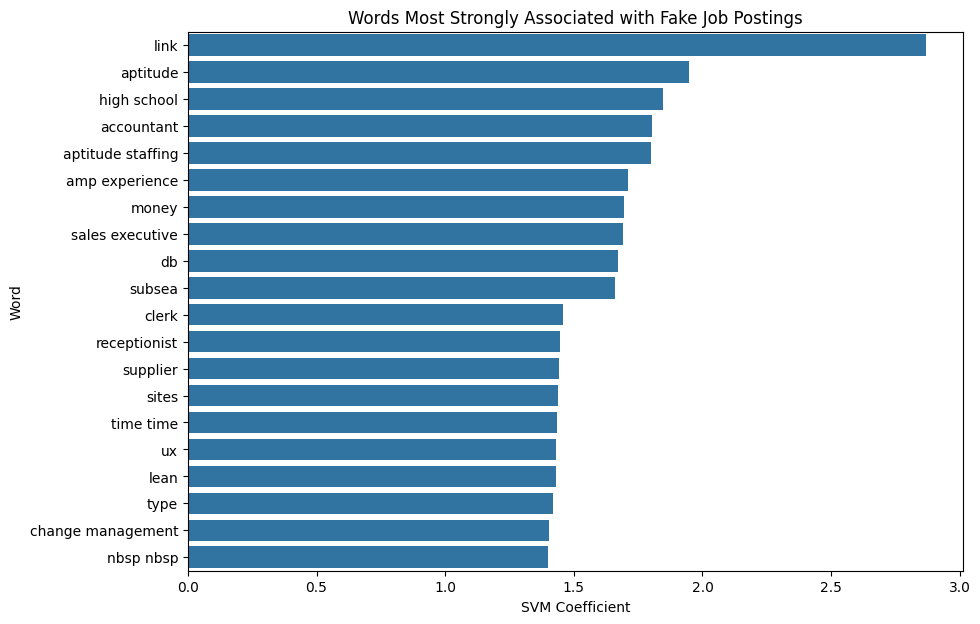

In [52]:
#visualising the fake job features (linear svm)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=fake_words,
    x="coefficient",
    y="word"
)

plt.title("Words Most Strongly Associated with Fake Job Postings")
plt.xlabel("SVM Coefficient")
plt.ylabel("Word")

plt.show()

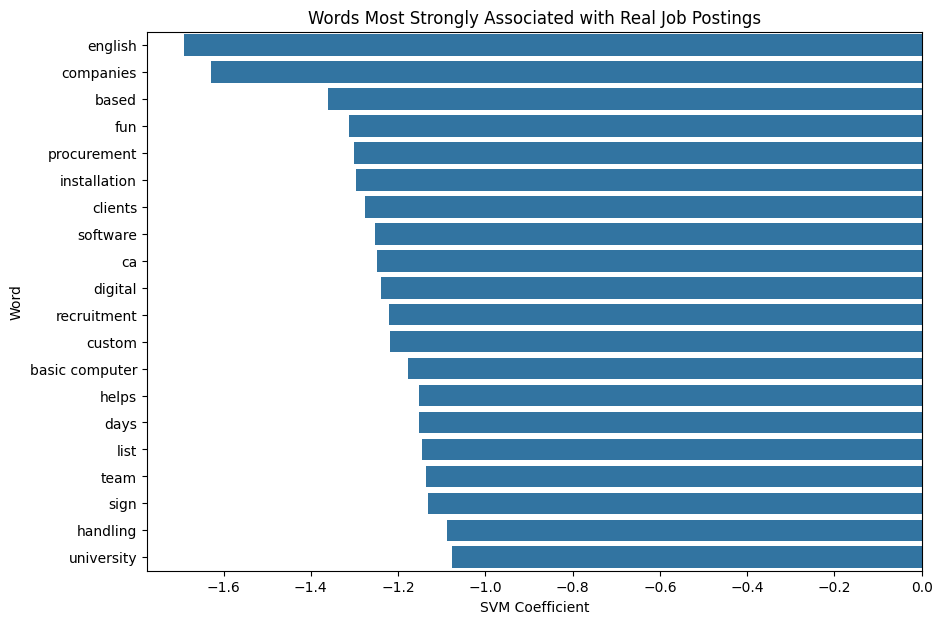

In [53]:
#visualising the real job features (linear svm)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=real_words,
    x="coefficient",
    y="word"
)

plt.title("Words Most Strongly Associated with Real Job Postings")
plt.xlabel("SVM Coefficient")
plt.ylabel("Word")

plt.show()

In [54]:
import pickle
import os

os.makedirs("model", exist_ok=True)

with open("model/best_model.pkl", "wb") as file:
    pickle.dump(best_model, file)

with open("model/vectorizer.pkl", "wb") as file:
    pickle.dump(vectorizer, file)

print("Model and vectorizer saved successfully.")

Model and vectorizer saved successfully.


In [55]:
#testing svm on individual job postings

def predict_job(text):
    cleaned = clean_text(text)
    transformed = vectorizer.transform([cleaned])

    prediction = best_model.predict(transformed)[0]
    score = best_model.decision_function(transformed)[0]

    if prediction == 1:
        result = "Potentially Fraudulent"
    else:
        result = "Likely Legitimate"

    return result, score

In [56]:
test_job = """
We are looking for a motivated administrative assistant.
The successful candidate will support our team with
customer communication, scheduling and general administration.
Previous experience is preferred. The position is based in London.
"""

result, score = predict_job(test_job)

print("Prediction:", result)
print("Decision score:", score)

Prediction: Likely Legitimate
Decision score: -0.4529481495844854


In [57]:
test_fake_job = """
URGENT! Work from home and earn £5,000 per week!
No experience required. Immediate hiring.
Simply click the link and send your bank details to receive
your starter payment. Make money quickly with this amazing opportunity!
"""

result, score = predict_job(test_fake_job)

print("Prediction:", result)
print("Decision score:", score)

Prediction: Potentially Fraudulent
Decision score: 1.6242927349329261


In [58]:
#checking decision scores

scores = best_model.decision_function(X_test_tfidf)

print("Minimum score:", scores.min())
print("Maximum score:", scores.max())
print("Median score:", np.median(scores))

Minimum score: -3.0111009388935375
Maximum score: 2.6141127542872504
Median score: -1.2911030837968078


In [59]:
print("Fake job scores:")
print(scores[y_test.values == 1][:20])

print("\nReal job scores:")
print(scores[y_test.values == 0][:20])

Fake job scores:
[ 0.62215981  1.11776146  1.01816379  0.99059281  1.01816379  1.11054854
  0.96862804  0.53087469  0.99615282  0.86769246 -0.71935258 -0.080042
 -0.20282333  0.91931415 -0.707326    0.99275522 -0.29770137 -0.07208537
  0.99615282  0.90588633]

Real job scores:
[ 0.07765563 -0.92515796 -1.55540363 -1.88958231 -1.44210812 -1.64937629
 -1.42172339 -1.33000168 -1.43743686 -1.29899389 -1.56904958 -1.49644869
 -2.00290476 -1.32700509 -0.88862295 -1.35622585 -1.68396149 -1.38798515
 -1.12002676 -0.95057699]


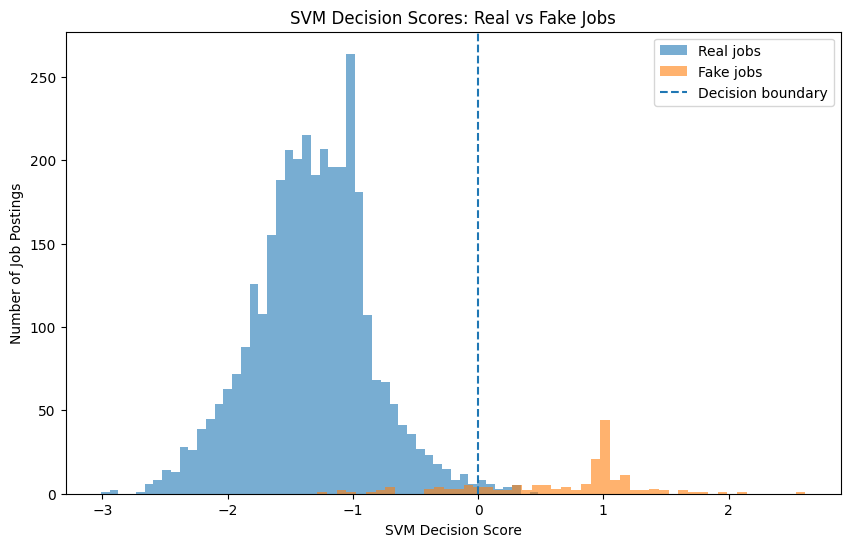

In [60]:
#visualising decision boundary

plt.figure(figsize=(10, 6))

plt.hist(
    scores[y_test.values == 0],
    bins=50,
    alpha=0.6,
    label="Real jobs"
)

plt.hist(
    scores[y_test.values == 1],
    bins=50,
    alpha=0.6,
    label="Fake jobs"
)

plt.axvline(
    0,
    linestyle="--",
    label="Decision boundary"
)

plt.xlabel("SVM Decision Score")
plt.ylabel("Number of Job Postings")
plt.title("SVM Decision Scores: Real vs Fake Jobs")
plt.legend()

plt.show()

In [61]:
#testing false positives and negatives

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, svm_predictions)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 3378
False Positives: 25
False Negatives: 30
True Positives: 143


In [62]:
#comparing word frequencies for real/fake and fake10k

from collections import Counter
import pandas as pd
import numpy as np

# Combine all real job text
real_text = " ".join(
    real_fake.loc[real_fake["fraudulent"] == 0, "clean_text"]
)

# Combine all fake job text from the separate 10K dataset
fake_text = " ".join(fake10k["clean_text"])

# Count words
real_word_counts = Counter(real_text.split())
fake_word_counts = Counter(fake_text.split())

# Number of words in each dataset
total_real_words = sum(real_word_counts.values())
total_fake_words = sum(fake_word_counts.values())

print("Total real words:", total_real_words)
print("Total fake words:", total_fake_words)

Total real words: 6858454
Total fake words: 300386


In [63]:
#calculate normalised word frequency

word_comparison = pd.DataFrame({
    "word": list(set(real_word_counts.keys()) | set(fake_word_counts.keys()))
})

word_comparison["real_count"] = word_comparison["word"].apply(
    lambda x: real_word_counts[x]
)

word_comparison["fake_count"] = word_comparison["word"].apply(
    lambda x: fake_word_counts[x]
)

word_comparison["real_frequency"] = (
    word_comparison["real_count"] / total_real_words * 10000
)

word_comparison["fake_frequency"] = (
    word_comparison["fake_count"] / total_fake_words * 10000
)

In [64]:
word_comparison["fake_vs_real_ratio"] = (
    (word_comparison["fake_frequency"] + 0.01) /
    (word_comparison["real_frequency"] + 0.01)
)

In [65]:
#remove extremely rare words

word_comparison_filtered = word_comparison[
    (word_comparison["fake_count"] >= 20) &
    (word_comparison["real_count"] >= 20)
].copy()

In [66]:
#finding words disproportionately common in fake postings

fake_disproportionate = word_comparison_filtered.sort_values(
    "fake_vs_real_ratio",
    ascending=False
)

print(
    fake_disproportionate[
        [
            "word",
            "fake_frequency",
            "real_frequency",
            "fake_vs_real_ratio"
        ]
    ].head(30)
)

               word  fake_frequency  real_frequency  fake_vs_real_ratio
88359          earn      332.904996        0.527816          619.013109
2618      immediate      332.904996        0.752356          436.692219
32304         meals       66.081642        0.313482          204.313370
25842         jones        7.257329        0.037909          151.688941
24168           plc       19.841138        0.123935          148.215117
53665         basic      332.904996        2.580757          128.501073
75598        hiring      332.904996        2.614292          126.858986
33577          sign       71.175088        0.558435          125.229977
31478     chartered        5.759256        0.036451          124.199937
29485          week      335.135459        2.943812          113.462010
42256       contact      332.904996        3.072121          108.014904
5639       flexible      398.420699        3.785110          104.985295
74252   established      332.904996        3.286455          100

In [67]:
#words more common in real postings

real_disproportionate = word_comparison_filtered.sort_values(
    "fake_vs_real_ratio",
    ascending=True
)

print(
    real_disproportionate[
        [
            "word",
            "fake_frequency",
            "real_frequency",
            "fake_vs_real_ratio"
        ]
    ].head(30)
)

             word  fake_frequency  real_frequency  fake_vs_real_ratio
9129          the        1.930849      289.296976            0.006709
48076          to        2.596659      295.750325            0.008813
29204          of        2.829692      218.240146            0.013011
77722           a        3.728536      236.408963            0.015813
79849         for        2.230463      119.273236            0.018783
85463        with        2.563368      129.618133            0.019852
55278          we        2.263754      113.858021            0.019968
72316         our        1.997430       96.042053            0.020899
24403         you        1.964139       87.445363            0.022573
23163           s        1.298329       41.264402            0.031698
19034          be        2.064011       57.727295            0.035922
18813  experience        2.097301       55.608742            0.037888
16143        that        1.964139       50.324752            0.039220
53582          or   

In [68]:
#visualising fake postings

top_fake_words = fake_disproportionate.head(15).copy()

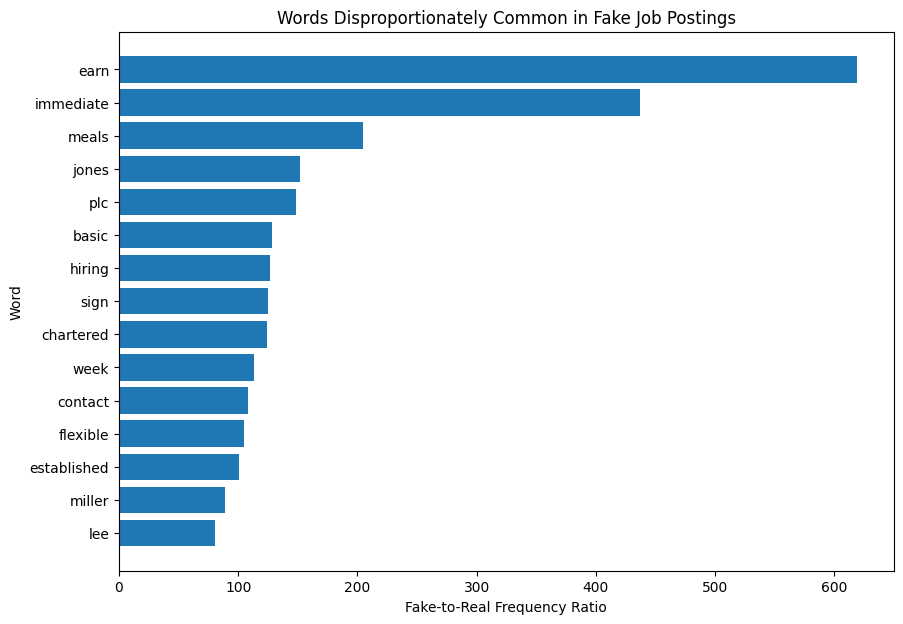

In [69]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

y_positions = np.arange(len(top_fake_words))

plt.barh(
    y_positions,
    top_fake_words["fake_vs_real_ratio"]
)

plt.yticks(
    y_positions,
    top_fake_words["word"]
)

plt.xlabel("Fake-to-Real Frequency Ratio")
plt.ylabel("Word")
plt.title("Words Disproportionately Common in Fake Job Postings")

plt.gca().invert_yaxis()

plt.show()

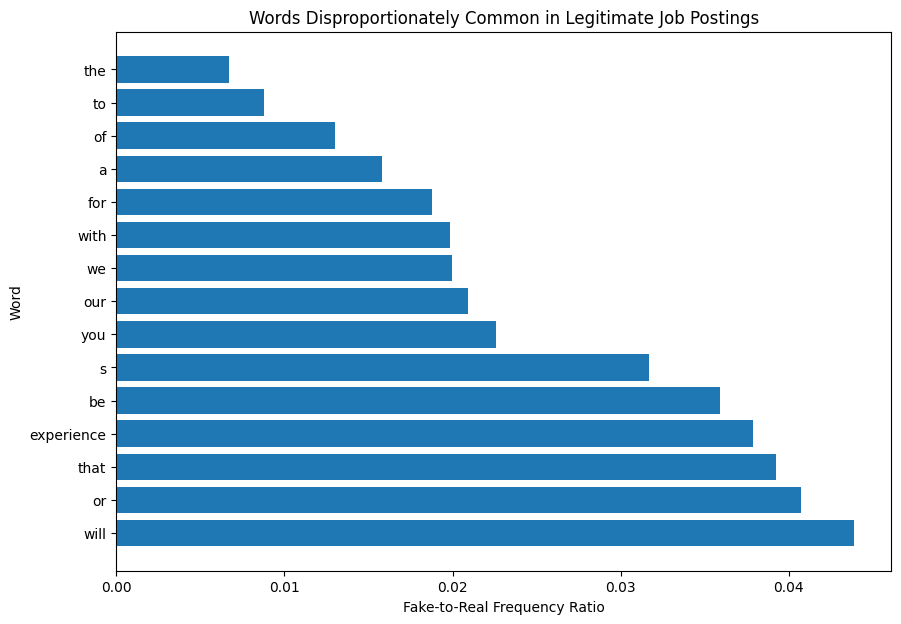

In [70]:
#visualising real jobs

top_real_words = real_disproportionate.head(15).copy()

plt.figure(figsize=(10, 7))

y_positions = np.arange(len(top_real_words))

plt.barh(
    y_positions,
    top_real_words["fake_vs_real_ratio"]
)

plt.yticks(
    y_positions,
    top_real_words["word"]
)

plt.xlabel("Fake-to-Real Frequency Ratio")
plt.ylabel("Word")
plt.title("Words Disproportionately Common in Legitimate Job Postings")

plt.gca().invert_yaxis()

plt.show()

In [71]:
#common phrases for fake listings

from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    stop_words="english",
    ngram_range=(2, 2),
    min_df=20
)

# Fake jobs
fake_bigram_matrix = bigram_vectorizer.fit_transform(
    fake10k["clean_text"]
)

fake_bigrams = pd.DataFrame({
    "phrase": bigram_vectorizer.get_feature_names_out(),
    "fake_count": np.asarray(
        fake_bigram_matrix.sum(axis=0)
    ).flatten()
})

In [72]:
#common phrases for real listings

real_bigram_matrix = bigram_vectorizer.transform(
    real_fake.loc[
        real_fake["fraudulent"] == 0,
        "clean_text"
    ]
)

fake_bigrams["real_count"] = np.asarray(
    real_bigram_matrix.sum(axis=0)
).flatten()

In [73]:
fake_bigrams["fake_frequency"] = (
    fake_bigrams["fake_count"] /
    fake_bigrams["fake_count"].sum()
)

fake_bigrams["real_frequency"] = (
    fake_bigrams["real_count"] /
    fake_bigrams["real_count"].sum()
)

fake_bigrams["fake_vs_real_ratio"] = (
    (fake_bigrams["fake_frequency"] + 0.000001) /
    (fake_bigrams["real_frequency"] + 0.000001)
)

In [74]:
top_fake_bigrams = fake_bigrams.sort_values(
    "fake_vs_real_ratio",
    ascending=False
)

print(
    top_fake_bigrams[
        [
            "phrase",
            "fake_count",
            "real_count",
            "fake_vs_real_ratio"
        ]
    ].head(30)
)

                    phrase  fake_count  real_count  fake_vs_real_ratio
52           contact basic       10000           0        78628.478731
372         week immediate       10000           0        78628.478731
168         hiring contact       10000           0        78628.478731
176             hours sign        2067           0        16253.299854
269        plc established         596           0         4687.197732
211        llc established         560           0         4404.138809
333       sons established         553           0         4349.099574
331      smith established         157           0         1235.451416
190    johnson established         134           0         1054.608215
72       education officer         115           0          905.216005
375   williams established         110           0          865.902266
304       research officer          94           0          740.098300
24       brown established          94           0          740.098300
235   

In [75]:
#removing redudant phrases

bad_terms = [
    "nbsp",
    "amp",
    "http",
    "www"
]

pattern = "|".join(bad_terms)

fake_bigrams_clean = fake_bigrams[
    ~fake_bigrams["phrase"].str.contains(
        pattern,
        case=False,
        regex=True
    )
].copy()

In [76]:
print(
    fake_bigrams_clean[
        [
            "phrase",
            "fake_count",
            "real_count",
            "fake_vs_real_ratio"
        ]
    ]
    .sort_values(
        "fake_vs_real_ratio",
        ascending=False
    )
    .head(30)
)

                    phrase  fake_count  real_count  fake_vs_real_ratio
372         week immediate       10000           0        78628.478731
52           contact basic       10000           0        78628.478731
168         hiring contact       10000           0        78628.478731
176             hours sign        2067           0        16253.299854
269        plc established         596           0         4687.197732
211        llc established         560           0         4404.138809
333       sons established         553           0         4349.099574
331      smith established         157           0         1235.451416
190    johnson established         134           0         1054.608215
72       education officer         115           0          905.216005
375   williams established         110           0          865.902266
304       research officer          94           0          740.098300
24       brown established          94           0          740.098300
235   

In [77]:
#phrases common in fake postings but rare in real

meaningful_fake_bigrams = fake_bigrams_clean[
    (fake_bigrams_clean["fake_count"] >= 20) &
    (fake_bigrams_clean["real_count"] >= 20)
].copy()

meaningful_fake_bigrams = meaningful_fake_bigrams.sort_values(
    "fake_vs_real_ratio",
    ascending=False
)

print(
    meaningful_fake_bigrams[
        [
            "phrase",
            "fake_count",
            "real_count",
            "fake_vs_real_ratio"
        ]
    ].head(20)
)

                     phrase  fake_count  real_count  fake_vs_real_ratio
330              sign bonus        2067          27            3.404052
18          basic knowledge       10000         154            2.887704
138          flexible hours       11968         235            2.264809
173          hours flexible        1968          40            2.187840
301             remote work        1986          58            1.522721
59          degree required       10000         945            0.470603
14             armed forces          69          35            0.087820
335         speech language          36          21            0.076486
143        foreign language          35          25            0.062472
266       physical sciences          36          31            0.051818
212        local government          23          21            0.048963
166        higher education          57          52            0.048851
48   commercial residential          28          27            0

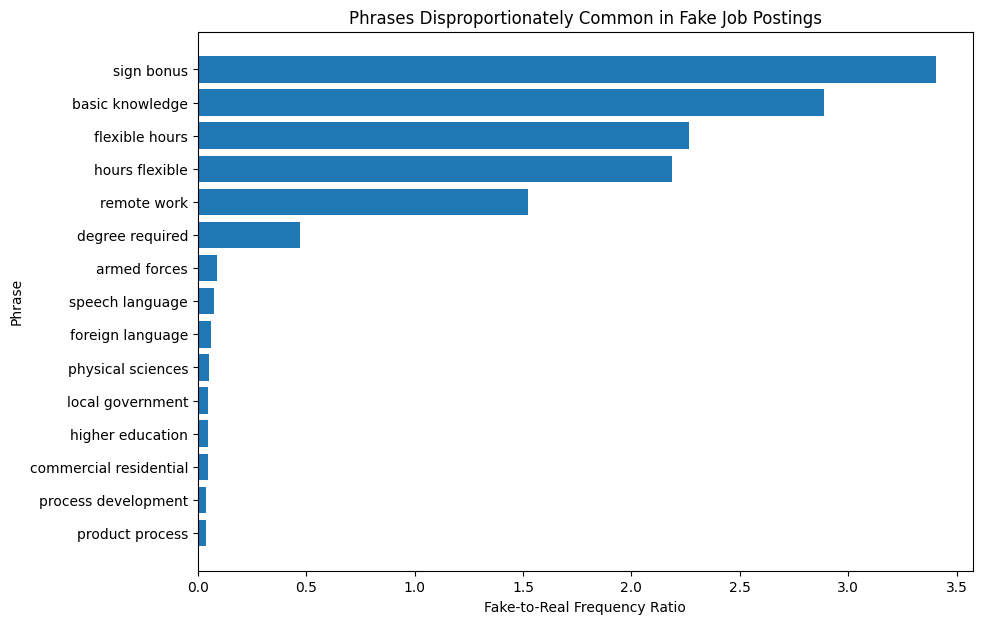

In [78]:
#visualize the strongest phrase

top_phrases = meaningful_fake_bigrams.head(15)

plt.figure(figsize=(10, 7))

y_positions = np.arange(len(top_phrases))

plt.barh(
    y_positions,
    top_phrases["fake_vs_real_ratio"]
)

plt.yticks(
    y_positions,
    top_phrases["phrase"]
)

plt.xlabel("Fake-to-Real Frequency Ratio")
plt.ylabel("Phrase")
plt.title("Phrases Disproportionately Common in Fake Job Postings")

plt.gca().invert_yaxis()

plt.show()

In [79]:
print("Total fake jobs:", len(fake10k))

print(
    "Unique full_text:",
    fake10k["full_text"].nunique()
)

print(
    "Unique clean_text:",
    fake10k["clean_text"].nunique()
)

Total fake jobs: 10000
Unique full_text: 10000
Unique clean_text: 10000


In [80]:
duplicate_count = fake10k["clean_text"].duplicated().sum()

print("Duplicate rows:", duplicate_count)
print(
    "Percentage duplicated:",
    duplicate_count / len(fake10k) * 100,
    "%"
)

Duplicate rows: 0
Percentage duplicated: 0.0 %


In [81]:
duplicate_jobs = (
    fake10k["clean_text"]
    .value_counts()
    .reset_index()
)

duplicate_jobs.columns = ["text", "count"]

print(duplicate_jobs.head(20))

                                                 text  count
0   company secretary gibson olson established imp...      1
1   engineer production lam dennis and white estab...      1
2   press photographer montes bailey and ortiz est...      1
3   clinical embryologist gates henderson and kenn...      1
4   land geomatics surveyor simon llc established ...      1
5   lighting technician broadcasting film video sp...      1
6   transport planner robinson richards establishe...      1
7   mudlogger wolfe hart and barrett established s...      1
8   soil scientist harper inc established case oth...      1
9   charity fundraiser beasley llc established sug...      1
10  meteorologist wise holt and chen established a...      1
11  waste management officer peters parks and roge...      1
12  commissioning editor henderson wu and perez es...      1
13  publishing rights manager alvarez coleman and ...      1
14  corporate investment banker montoya austin est...      1
15  systems analyst dudl

In [82]:
# Check how common the suspicious phrases really are

phrases_to_check = [
    "contact basic",
    "week immediate",
    "hiring contact",
    "earn week",
    "hours sign"
]

for phrase in phrases_to_check:
    count = fake10k["clean_text"].str.contains(
        phrase,
        regex=False
    ).sum()

    percentage = count / len(fake10k) * 100

    print(f"{phrase}: {count} jobs ({percentage:.2f}%)")

contact basic: 0 jobs (0.00%)
week immediate: 10000 jobs (100.00%)
hiring contact: 10000 jobs (100.00%)
earn week: 10000 jobs (100.00%)
hours sign: 2067 jobs (20.67%)


In [83]:
print("Unique titles:", fake10k["title"].nunique())
print("Unique descriptions:", fake10k["description"].nunique())
print("Unique company profiles:", fake10k["company_profile"].nunique())

print("\nMost common titles:")
print(fake10k["title"].value_counts().head(20))

Unique titles: 639
Unique descriptions: 10000
Unique company profiles: 9953

Most common titles:
title
Air cabin crew                                      30
Health physicist                                    28
Insurance broker                                    28
Textile designer                                    27
Gaffer                                              27
Television floor manager                            26
Surveyor, building control                          26
Forensic psychologist                               25
Public house manager                                25
Research scientist (maths)                          25
Exhibitions officer, museum/gallery                 25
Surveyor, rural practice                            24
Administrator, charities/voluntary organisations    24
Automotive engineer                                 24
Horticulturist, amenity                             24
Acupuncturist                                       24
Financial planner

In [84]:
print("\nMost common descriptions:")
print(fake10k["description"].value_counts().head(10))


Most common descriptions:
description
Impact kid without fight. Earn $5000/week! Immediate hiring. Contact now at timothy82@harrison.com.                 1
Center trouble your defense north. Earn $5000/week! Immediate hiring. Contact now at pharris@lewis.net.             1
By trade capital back. Earn $5000/week! Immediate hiring. Contact now at brighttimothy@ramirez-morales.com.         1
Trouble cup check how. Earn $5000/week! Immediate hiring. Contact now at pricejoshua@gutierrez.net.                 1
My address tonight after debate. Earn $5000/week! Immediate hiring. Contact now at parkerlacey@cook.com.            1
Detail relate risk policy at history. Earn $5000/week! Immediate hiring. Contact now at mgutierrez@gmail.com.       1
Step get catch teacher reality. Earn $5000/week! Immediate hiring. Contact now at berryandrew@sanchez-foley.com.    1
Society kid share still. Earn $5000/week! Immediate hiring. Contact now at yponce@yahoo.com.                        1
Case others grow 

In [85]:
# Look at the ending of the fake descriptions

fake10k["description"].str[-150:].head(10)

,description
0,Arm drive court sure vote. Earn $5000/week! Im...
1,Government whom its bed go tax tree black. Ear...
2,I member discuss follow way there nation. Earn...
3,House across wait approach face. Earn $5000/we...
4,Case best environmental full finally leader me...
5,That page party sell student cultural despite....
6,Evidence always item increase partner necessar...
7,Country situation skin. Earn $5000/week! Immed...
8,Song role during democratic. Earn $5000/week! ...
9,Nor upon style audience. Earn $5000/week! Imme...


In [86]:
template_phrases = [
    "Earn $5000/week!",
    "Immediate hiring.",
    "Contact now at"
]

for phrase in template_phrases:
    count = fake10k["description"].str.contains(
        phrase,
        regex=False,
        na=False
    ).sum()

    print(
        f"{phrase}: {count} / {len(fake10k)} "
        f"({count / len(fake10k) * 100:.2f}%)"
    )

Earn $5000/week!: 10000 / 10000 (100.00%)
Immediate hiring.: 10000 / 10000 (100.00%)
Contact now at: 10000 / 10000 (100.00%)


In [88]:
#creating streamlit app
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 50.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 50.7 MB/s eta 0:00:00


In [89]:
import streamlit as st
import pickle
import re


# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Job Scam Detector",
    page_icon="🔍",
    layout="centered"
)


# --------------------------------------------------
# LOAD MODEL
# --------------------------------------------------

@st.cache_resource
def load_model():

    with open("model/best_model.pkl", "rb") as file:
        model = pickle.load(file)

    with open("model/vectorizer.pkl", "rb") as file:
        vectorizer = pickle.load(file)

    return model, vectorizer


model, vectorizer = load_model()


# --------------------------------------------------
# TEXT CLEANING
# --------------------------------------------------

def clean_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove non-alphabetic characters
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# --------------------------------------------------
# PREDICTION
# --------------------------------------------------

def predict_job(text):

    cleaned = clean_text(text)

    transformed = vectorizer.transform([cleaned])

    prediction = model.predict(transformed)[0]

    decision_score = model.decision_function(transformed)[0]

    return prediction, decision_score


# --------------------------------------------------
# TITLE
# --------------------------------------------------

st.title("🔍 Job Scam Detector")

st.write(
    "Paste a job posting below and the machine learning model "
    "will assess whether it appears potentially fraudulent."
)

st.info(
    "This tool is a screening aid, not proof that a job is legitimate "
    "or fraudulent. Always verify the employer independently."
)


# --------------------------------------------------
# INPUT
# --------------------------------------------------

job_text = st.text_area(
    "Paste the job posting here:",
    height=300,
    placeholder=(
        "Paste the job title, company information, "
        "description, requirements and benefits..."
    )
)


# --------------------------------------------------
# PREDICT BUTTON
# --------------------------------------------------

if st.button("Analyze Job Posting"):

    if not job_text.strip():

        st.warning("Please paste a job posting first.")

    else:

        prediction, decision_score = predict_job(job_text)

        st.divider()

        # ------------------------------------------
        # RESULT
        # ------------------------------------------

        if prediction == 1:

            st.error("⚠️ Potentially Fraudulent")

            st.write(
                "The model identified patterns that are more "
                "associated with fraudulent job postings in its training data."
            )

        else:

            st.success("✅ Likely Legitimate")

            st.write(
                "The model identified patterns that are more "
                "associated with legitimate job postings in its training data."
            )


        # ------------------------------------------
        # MODEL SCORE
        # ------------------------------------------

        st.subheader("Model Score")

        st.write(
            f"Decision score: **{decision_score:.3f}**"
        )

        st.caption(
            "The Linear SVM uses a decision score rather than a probability. "
            "Scores above 0 indicate the model classified the posting as "
            "potentially fraudulent; scores below 0 indicate likely legitimate."
        )


# --------------------------------------------------
# ABOUT SECTION
# --------------------------------------------------

st.divider()

st.subheader("About this model")

st.write(
    """
    This application uses a Linear Support Vector Machine (SVM)
    trained on TF-IDF representations of job-posting text.

    The model was compared with Logistic Regression and Naive Bayes.
    Linear SVM achieved the strongest overall F1 score on the test set
    and was selected as the final model.
    """
)

st.caption(
    "Model performance: 98.46% accuracy | 85.12% precision | "
    "82.66% recall | 83.87% F1 score"
)

2026-10-08 17:24:00.823 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 17:24:00.831 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 17:24:00.847 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 17:24:01.221 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-08 17:24:01.224 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 17:24:01.227 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-08 17:24:01.231 Thread 'MainThread'

DeltaGenerator()

In [92]:
%%writefile app.py

import streamlit as st
import pickle
import re


# --------------------------------------------------
# PAGE CONFIGURATION
# --------------------------------------------------

st.set_page_config(
    page_title="Job Scam Detector",
    page_icon="🔍",
    layout="centered"
)


# --------------------------------------------------
# LOAD MODEL
# --------------------------------------------------

@st.cache_resource
def load_model():

    with open("model/best_model.pkl", "rb") as file:
        model = pickle.load(file)

    with open("model/vectorizer.pkl", "rb") as file:
        vectorizer = pickle.load(file)

    return model, vectorizer


model, vectorizer = load_model()


# --------------------------------------------------
# TEXT CLEANING
# --------------------------------------------------

def clean_text(text):

    text = str(text).lower()

    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    text = re.sub(r"\S+@\S+", " ", text)

    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text


# --------------------------------------------------
# PREDICTION
# --------------------------------------------------

def predict_job(text):

    cleaned = clean_text(text)

    transformed = vectorizer.transform([cleaned])

    prediction = model.predict(transformed)[0]

    decision_score = model.decision_function(transformed)[0]

    return prediction, decision_score


# --------------------------------------------------
# TITLE
# --------------------------------------------------

st.title("🔍 Job Scam Detector")

st.write(
    "Paste a job posting below and the machine learning model "
    "will assess whether it appears potentially fraudulent."
)

st.info(
    "This tool is a screening aid, not proof that a job is legitimate "
    "or fraudulent. Always verify the employer independently."
)


# --------------------------------------------------
# INPUT
# --------------------------------------------------

job_text = st.text_area(
    "Paste the job posting here:",
    height=300,
    placeholder=(
        "Paste the job title, company information, "
        "description, requirements and benefits..."
    )
)


# --------------------------------------------------
# PREDICT BUTTON
# --------------------------------------------------

if st.button("Analyze Job Posting"):

    if not job_text.strip():

        st.warning("Please paste a job posting first.")

    else:

        prediction, decision_score = predict_job(job_text)

        st.divider()

        if prediction == 1:

            st.error("⚠️ Potentially Fraudulent")

            st.write(
                "The model identified patterns that are more "
                "associated with fraudulent job postings in its training data."
            )

        else:

            st.success("✅ Likely Legitimate")

            st.write(
                "The model identified patterns that are more "
                "associated with legitimate job postings in its training data."
            )

        st.subheader("Model Score")

        st.write(
            f"Decision score: **{decision_score:.3f}**"
        )

        st.caption(
            "The Linear SVM uses a decision score rather than a probability. "
            "Scores above 0 indicate a potentially fraudulent classification; "
            "scores below 0 indicate a likely legitimate classification."
        )


# --------------------------------------------------
# ABOUT
# --------------------------------------------------

st.divider()

st.subheader("About this model")

st.write(
    """
    This application uses a Linear Support Vector Machine (SVM)
    trained on TF-IDF representations of job-posting text.

    The model was compared with Logistic Regression and Naive Bayes.
    Linear SVM achieved the strongest overall F1 score on the test set
    and was selected as the final model.
    """
)

st.caption(
    "Model performance: 98.46% accuracy | 85.12% precision | "
    "82.66% recall | 83.87% F1 score"
)

Writing app.py


In [93]:
import os

print(os.path.exists("app.py"))

True


In [94]:
!pip install -q streamlit pyngrok

In [95]:
!streamlit run app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [96]:
!cat /content/streamlit.log



2026-10-08 17:27:37.846 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.23.208.145:8501



In [99]:
from pyngrok import ngrok

ngrok.set_auth_token("3KQCrbALN9AXqTvMJYRqk05bGrS_6S8wVJscuarTfHSTPevpA")

public_url = ngrok.connect(8501)

print("Public URL:", public_url)

Public URL: NgrokTunnel: "https://jasmine-enunciate-dominoes.ngrok-free.dev" -> "http://localhost:8501"


In [100]:
from google.colab import files

files.download("model/best_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [101]:
files.download("model/vectorizer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [102]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [103]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles:")
for root, dirs, files in os.walk("."):
    for file in files:
        print(os.path.join(root, file))

Current directory:
/content

Files:
./streamlit.log
./fake_jobs_10k.csv
./real_fake_jobs.csv
./app.py
./.config/gce
./.config/.last_opt_in_prompt.yaml
./.config/.last_update_check.json
./.config/default_configs.db
./.config/.last_survey_prompt.yaml
./.config/active_config
./.config/config_sentinel
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/configurations/config_default
./.config/logs/2026.10.02/13.50.15.366402.log
./.config/logs/2026.10.02/13.50.21.004336.log
./.config/logs/2026.10.02/13.50.21.555054.log
./.config/logs/2026.10.02/13.50.14.261149.log
./.config/logs/2026.10.02/13.49.46.128557.log
./.config/logs/2026.10.02/13.50.08.874802.log
./model/best_model.pkl
./model/vectorizer.pkl
./sample_data/README.md
./sample_data/anscombe.json
./sample_data/california_housing_train.csv
./sample_data/mnist_test.csv
./sample_data/california_housing_test.csv
./sample_data/mnist_train_small.csv
